In [380]:
from anemone.forwards import Forward
from anemone.experiment import Loop, Receiver, Waveform, ButterworthFilter
import torch
import numpy as np

In [403]:
class ButterworthFilter1:
    def __init__(self, fcut, order=1):
        self.fcut = fcut
        self.order = order

    def omega_filter(self, omega):
        return 1.0 / torch.sqrt((1.0 + (omega / (2.*np.pi*self.fcut)) ** (2 * self.order)))
    
    def __call__(self, f):
        return self.omega_filter(2.*np.pi*f)

class ButterworthFilter:
    def __init__(self, fcut, order=1):
        self.fcut = fcut
        self.order = order

    def omega_filter(self, omega):
        return self.__call__(omega/c.twopi)
    
    def __call__(self, f):
        s = 1j*f/self.fcut
        if   self.order==1: recip_resp = (s+1)
        elif self.order==2: recip_resp = (s**2 + s*2**(1/2) + 1)
        elif self.order==3: recip_resp = (s**2 + s + 1)*(1+s)
        elif self.order==4: recip_resp = (s**2 + 1.84776*s+1)*(s**2 + 0.76537*s+1)
        return 1./torch.sqrt(recip_resp)

c:\Users\au646858\Miniconda3\envs\em1d\Lib\site-packages\matplotlib\cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\au646858\Miniconda3\envs\em1d\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


(-0.1, 1.1)

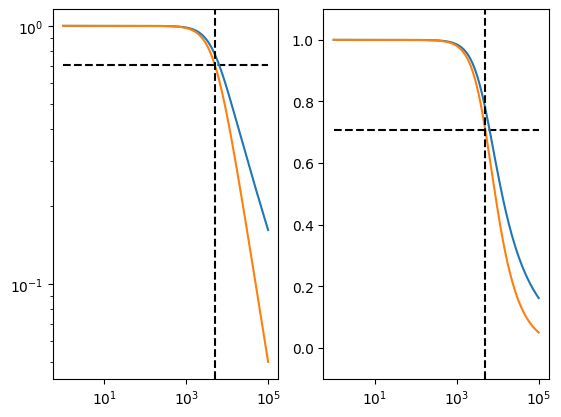

In [404]:
f = torch.logspace(0, 5, 1001, dtype=torch.double)
fig,axs = plt.subplots(1,2)
axs[0].loglog(f, torch.ones_like(f)/np.sqrt(2), 'k--')
axs[1].plot(f, torch.ones_like(f)/np.sqrt(2), 'k--')

bf0 = ButterworthFilter(5e3)
bf1 = ButterworthFilter1(5e3)

axs[0].loglog(f, bf0(f).numpy())
axs[0].loglog(f, bf1(f).numpy())
axs[1].plot(f, bf0(f).numpy())
axs[1].plot(f, bf1(f).numpy())


# axs[1].plot(f, res.imag, f'C{i}--')


ylim = axs[0].get_ylim()
axs[0].loglog([5e3, 5e3], ylim, 'k--')
axs[1].plot([5e3, 5e3], [-0.1, 1.1], 'k--')
axs[0].set_ylim(ylim)
axs[1].set_xscale('log')
axs[1].set_ylim(-0.1, 1.1)

In [442]:
class Hfunc:
    def __init__(self, b,a):
        self.b = b
        self.a = a

    def __call__(self, f):
        return (np.polyval(self.b, 1j*f)/np.polyval(self.a, 1j*f))#real
    
    def omega_filter(self, omega):
        return self.__call__(0.5*omega/np.pi)

(-0.1, 1.1)

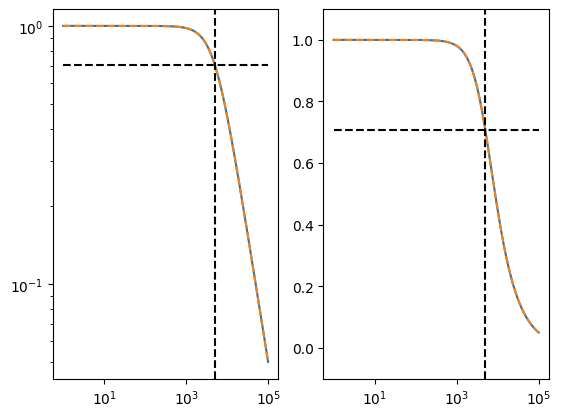

In [443]:
fs = 1e6
fcut = 5e3
b, a = signal.butter(1, fcut, output='ba', analog=True)
w, h = signal.freqs(b, a)





f = torch.logspace(0, 5, 1001, dtype=torch.double)
fig,axs = plt.subplots(1,2)
axs[0].loglog(f, torch.ones_like(f)/np.sqrt(2), 'k--')
axs[1].plot(f, torch.ones_like(f)/np.sqrt(2), 'k--')

bf0 = ButterworthFilter1(fcut)
#bf1 = Hfunc(b[::-1],a[::-1])
bf1 = Hfunc(b,a)

H = abs(bf1(f))
#H = b[0] / (a[1] + a[0]*1j*f)


axs[0].loglog(f, bf0(f).numpy())
axs[0].loglog(f, H, '--')
# axs[0].loglog(w, abs(h), 'r--')

axs[1].plot(f, bf0(f).numpy())
axs[1].plot(f, H, '--')
# axs[1].plot(w, abs(h), 'r--')


# axs[1].plot(f, res.imag, f'C{i}--')


ylim = axs[0].get_ylim()
axs[0].loglog([fcut, fcut], ylim, 'k--')
axs[1].plot([fcut, fcut], [-0.1, 1.1], 'k--')
axs[0].set_ylim(ylim)
axs[1].set_xscale('log')
axs[1].set_ylim(-0.1, 1.1)

(-0.1, 1.1)

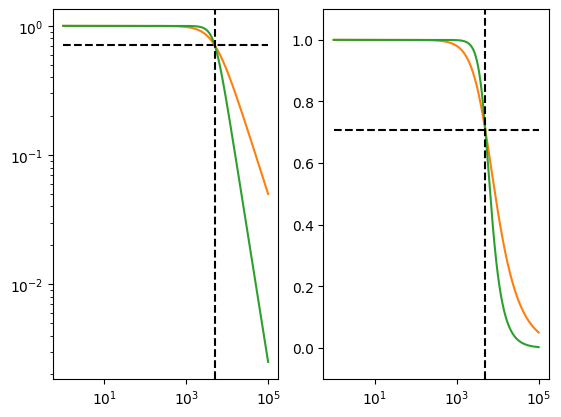

In [444]:
f = torch.logspace(0, 5, 1001, dtype=torch.double)
fig,axs = plt.subplots(1,2)
axs[0].loglog(f, torch.ones_like(f)/np.sqrt(2), 'k--')
axs[1].plot(f, torch.ones_like(f)/np.sqrt(2), 'k--')
for i in range(1, 3):
    bf1 = ButterworthFilter1(5e3, i)
    res = bf1(f)
    axs[0].loglog(f, np.abs(res), f'C{i}-')
    axs[1].plot(f, res.real, f'C{i}-')
    # axs[1].plot(f, res.imag, f'C{i}--')


ylim = axs[0].get_ylim()
axs[0].loglog([5e3, 5e3], ylim, 'k--')
axs[1].plot([5e3, 5e3], [-0.1, 1.1], 'k--')
axs[0].set_ylim(ylim)
axs[1].set_xscale('log')
axs[1].set_ylim(-0.1, 1.1)

In [445]:
tx = Loop.square(40)
rx = Receiver()
t = torch.logspace(-5, -3, 32)

w, h = signal.freqs(b, a)


fcut = 1e4


bf1 = ButterworthFilter1(fcut, order=1)
b, a = signal.butter(1, fcut, output='ba', analog=True)
bf2 = Hfunc(b,a)

fwr0 = Forward(tx, rx, t)
fwr1 = Forward(tx, rx, t, filterfunc=bf1)
fwr2 = Forward(tx, rx, t, filterfunc=bf2)

In [446]:
rho = torch.tensor([40, 80,50])
thickness = torch.tensor([10, 20])*2

dbdt0 = fwr0(rho, thickness)
dbdt1 = fwr1(rho, thickness)
dbdt2 = fwr2(rho, thickness)

In [447]:
from scipy.signal import butter, lfilter

In [448]:
from anemone.experiment import lamontagne


def intMat(t_in, t_out):
    t_out = t_out.to(t_in.dtype)
    logT = torch.log(t_in)#.cpu()
    dT = logT[1]-logT[0]
    t2t = torch.nan_to_num(lamontagne((torch.log(t_out)[:,None]-logT[None,:])/dT))
    return t2t

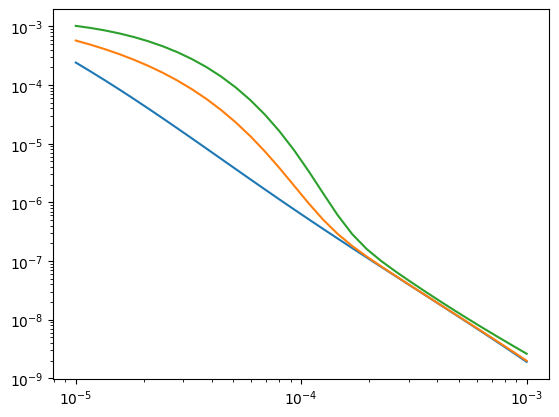

In [449]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure()
plt.loglog(t, dbdt0.numpy())
plt.loglog(t, dbdt1.numpy())
plt.loglog(t, dbdt2.numpy())

In [98]:
from numpy import convolve
def my_filtfilt(b, a, x):
    ab = b
    ab[:-1] += -a[1:]
    y1 = convolve(x, ab, mode='full')
    return y1[len(b)-1:]#*a[1]

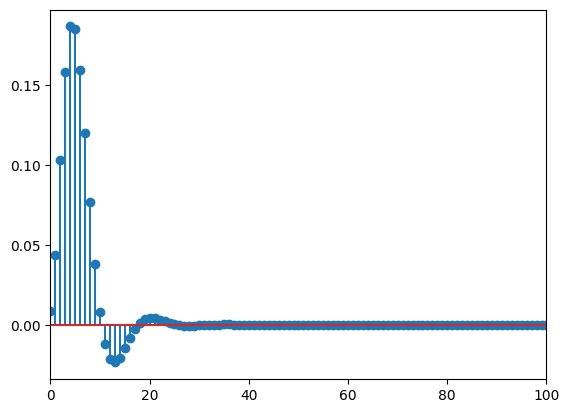

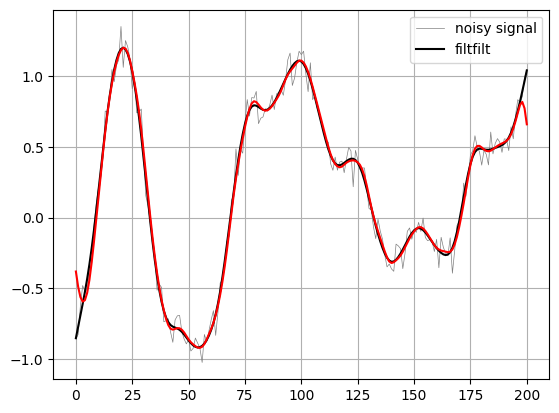

In [182]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
rng = np.random.default_rng()
t = np.linspace(-1, 1, 201)
t2 = t#[:-1]
x = (np.sin(2*np.pi*0.75*t*(1-t) + 2.1) +
     0.1*np.sin(2*np.pi*1.25*t + 1) +
     0.18*np.cos(2*np.pi*3.85*t))
xn = x + rng.standard_normal(len(t)) * 0.08

b, a = signal.butter(3, 0.15, output='ba')

X = np.fft.rfft(xn)

w,H = signal.freqz(b, a)

frq,X = np.fft.rfftfreq(len(xn), d=t[1]-t[0]), np.fft.rfft(xn)



h = np.fft.irfft(H)

#c,A,pk = signal.residuez(b, a)

#t,h = signal.impulse((b, a))


y2 = np.convolve(xn, h, mode='full')[len(b):]
y2 = y2[:len(xn)]    
#[len(b)//2:-len(b)//2+1]
# y2 /= y2.max()



plt.figure()
plt.stem(h)
plt.xlim(0, 100)

y = signal.filtfilt(b, a, xn)
# y2 = my_filtfilt(b, a, xn)

# y = y/y.max()

plt.figure()
plt.plot(xn,  'gray', linewidth=0.5)
plt.plot(y, 'k')
plt.plot(y2, 'r')
plt.legend(('noisy signal',  'filtfilt'), loc='best')
plt.grid(True)
plt.show()

<StemContainer object of 3 artists>

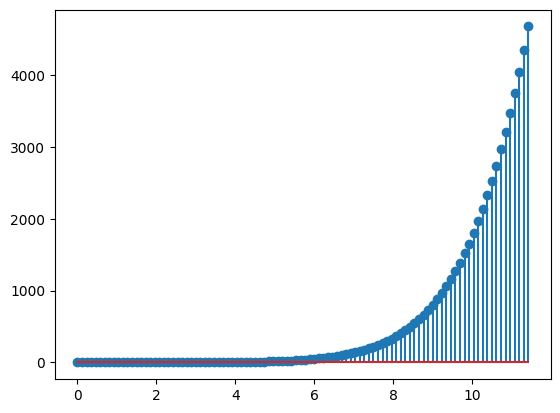

In [149]:
from scipy import signal
#system = ([1.0], [1.0, 2.0, 1.0])
t, y = signal.impulse(signal.butter(5, 0.15, output='ba'))
import matplotlib.pyplot as plt
plt.stem(t, y)

c:\Users\au646858\Miniconda3\envs\em1d\Lib\site-packages\numpy\ma\core.py:3387: ComplexWarning: Casting complex values to real discards the imaginary part
  _data[indx] = dval


<StemContainer object of 3 artists>

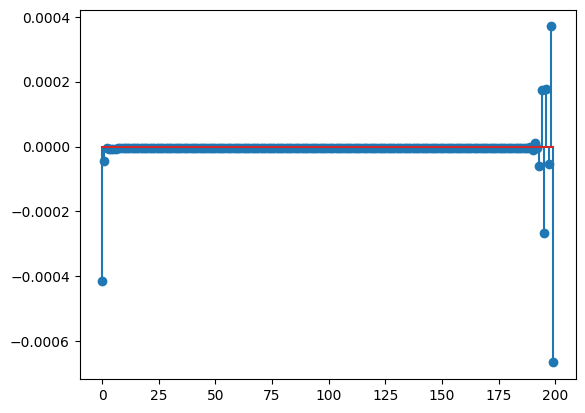

In [129]:
plt.figure()
plt.stem(h)